# Frequent Word Analysis — Twain vs. Reference Corpora

**Purpose:** Identifies the most distinctive high-frequency words in Twain's corpus and measures their relative frequency against both reference corpora. Two passes are run: (1) a corpus-wide frequent-word analysis that finds Twain's most over-represented words; (2) a targeted analysis of two manually curated word lists (first-person focalization markers and colloquial/evaluative terms).

**Method:** Raw frequency counting + relative frequency (per 10k); difference scores (Twain/10k − reference/10k) to rank distinctiveness. Log-likelihood tests added in later cells.

**Inputs:** All three corpora (Twain, child, adult).

**Output:** Sorted frequency tables; targeted comparison tables.

**Used in:** Chapter 4, frequent-word analysis and lexical distinctiveness discussion. Cross-validates McKay1.ipynb findings.

**Note:** This notebook went through several iterations (visible in the repeated cell blocks below). The **final versions** of each analysis are the last occurrence of each cell type. Earlier versions are retained for audit purposes.


In [1]:
from pathlib import Path
from collections import Counter
import re
import pandas as pd

BASE_PATH = Path("/Users/manalaltammami/Desktop/twain_child_corpus")
TOKEN_PATTERN = re.compile(r"[a-z]+(?:['-][a-z]+)*")

def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower().replace("’", "'"))

twain_files = ['Tom_Sawyer_narrative.txt', 'Huckleberry_Finn_narrative.txt', 'Prince_and_the_Pauper_narrative.txt']

child_files = ['Ragged_Dick_narrative.txt', 'Little_Women_narrative.txt', 'An_Old_Fashioned_Girl_narrative.txt', 'Toby_Tyler_narrative.txt', 'Five_Little_Peppers_narrative.txt', 'Hoosier_Schoolboy_narrative.txt', 'Little_Lord_Fauntleroy_narrative.txt', 'The_Story_of_Patsy_narrative.txt']

adult_files = ['Silas_Lapham_narrative.txt', 'Ministers_Charge_narrative.txt', 'Hazard_New_Fortunes_narrative.txt', 'Portrait_of_a_Lady_narrative.txt', 'Bostonians_narrative.txt', 'Washington_Square_narrative.txt', 'Pointed_Firs_narrative.txt', 'Deephaven_narrative.txt', 'Country_Doctor_narrative.txt', 'Awakening_narrative.txt', 'Graysons_narrative.txt', 'McTeague_narrative.txt', 'Octopus_narrative.txt', 'Red_Badge_of_Courage_narrative.txt', 'Maggie_narrative.txt', 'Main_Travelled_Roads_narrative.txt', 'Old_Creole_Days_narrative.txt', 'Conjure_Woman_narrative.txt', 'Looking_Backward_narrative.txt', 'Theron_Ware_narrative.txt', 'Sister_Carrie_narrative.txt', 'Summer_narrative.txt', 'Scarlet_Letter_narrative.txt', 'Seven_Gables_narrative.txt', 'Moby_Dick_narrative.txt', 'Aspern_Papers_narrative.txt', 'Bartleby_narrative.txt', 'Benito_Cereno_narrative.txt']

EXPECTED_BOOK_TOKENS = {'Tom_Sawyer_narrative.txt': 70518, 'Huckleberry_Finn_narrative.txt': 110729, 'Prince_and_the_Pauper_narrative.txt': 67007, 'Ragged_Dick_narrative.txt': 47722, 'Little_Women_narrative.txt': 185825, 'An_Old_Fashioned_Girl_narrative.txt': 101818, 'Toby_Tyler_narrative.txt': 50233, 'Five_Little_Peppers_narrative.txt': 69400, 'Hoosier_Schoolboy_narrative.txt': 36080, 'Little_Lord_Fauntleroy_narrative.txt': 58627, 'The_Story_of_Patsy_narrative.txt': 11359, 'Silas_Lapham_narrative.txt': 129245, 'Ministers_Charge_narrative.txt': 115995, 'Hazard_New_Fortunes_narrative.txt': 163596, 'Portrait_of_a_Lady_narrative.txt': 225399, 'Bostonians_narrative.txt': 162770, 'Washington_Square_narrative.txt': 64180, 'Pointed_Firs_narrative.txt': 41980, 'Deephaven_narrative.txt': 54924, 'Country_Doctor_narrative.txt': 89552, 'Awakening_narrative.txt': 49937, 'Graysons_narrative.txt': 91482, 'McTeague_narrative.txt': 113374, 'Octopus_narrative.txt': 196738, 'Red_Badge_of_Courage_narrative.txt': 46161, 'Maggie_narrative.txt': 22703, 'Main_Travelled_Roads_narrative.txt': 85788, 'Old_Creole_Days_narrative.txt': 68616, 'Conjure_Woman_narrative.txt': 37553, 'Looking_Backward_narrative.txt': 77303, 'Theron_Ware_narrative.txt': 119128, 'Sister_Carrie_narrative.txt': 156121, 'Summer_narrative.txt': 57454, 'Scarlet_Letter_narrative.txt': 68587, 'Seven_Gables_narrative.txt': 103524, 'Moby_Dick_narrative.txt': 209312, 'Aspern_Papers_narrative.txt': 39083, 'Bartleby_narrative.txt': 14456, 'Benito_Cereno_narrative.txt': 31472}

corpora = {"Twain": twain_files, "Child": child_files, "Adult": adult_files}
expected_totals = {"Twain": 248254, "Child": 561064, "Adult": 2636433}
all_files = [name for files in corpora.values() for name in files]
if len(all_files) != 39 or len(set(all_files)) != 39:
    raise ValueError("Expected 39 unique narrative files.")
missing = [name for name in all_files if not (BASE_PATH / name).is_file()]
if missing:
    raise FileNotFoundError("Missing narrative files:\n" + "\n".join(missing))

frequencies = {}
totals = {}
book_rows = []
for label, files in corpora.items():
    freq = Counter()
    for filename in files:
        tokens = tokenize((BASE_PATH / filename).read_text(encoding="utf-8"))
        if len(tokens) != EXPECTED_BOOK_TOKENS[filename]:
            raise ValueError(f"{filename}: {len(tokens):,} tokens; expected {EXPECTED_BOOK_TOKENS[filename]:,}. Check this file before continuing.")
        freq.update(tokens)
        book_rows.append({"Corpus": label, "File": filename, "Tokens": len(tokens)})
    total = sum(freq.values())
    if total != expected_totals[label]:
        raise ValueError(f"{label}: {total:,} tokens; expected {expected_totals[label]:,}.")
    frequencies[label] = freq
    totals[label] = total
    print(f"{label}: {total:,} tokens")

twain_freq, child_freq, adult_freq = [frequencies[x] for x in corpora]
N_twain, N_child, N_adult = [totals[x] for x in corpora]
df_book_tokens = pd.DataFrame(book_rows)
print("\nAll totals match the narrative-only lexical-richness results.")


Twain: 248,254 tokens
Child: 561,064 tokens
Adult: 2,636,433 tokens

All totals match the narrative-only lexical-richness results.


In [3]:
import pandas as pd

target_words = ["and", "then", "so", "but"]

rows = []

for word in target_words:
    rows.append({
        "Word": word,
        "Twain count": twain_freq[word],
        "Twain per 10k": twain_freq[word] / N_twain * 10000,
        "Child count": child_freq[word],
        "Child per 10k": child_freq[word] / N_child * 10000,
        "Adult count": adult_freq[word],
        "Adult per 10k": adult_freq[word] / N_adult * 10000,
    })

df_connectives = pd.DataFrame(rows)

print(df_connectives.round(3).to_string(index=False))

Word  Twain count  Twain per 10k  Child count  Child per 10k  Adult count  Adult per 10k
 and        12491        503.154        21404        381.489        75110        284.893
then         1214         48.902         1407         25.077         5311         20.145
  so         1628         65.578         3266         58.211         9978         37.847
 but         2157         86.887         3826         68.192        17538         66.522


In [5]:
import math

def g2_test(k1, n1, k2, n2):
    observed = [
        [k1, n1 - k1],
        [k2, n2 - k2]
    ]

    row_totals = [n1, n2]
    column_totals = [k1 + k2, n1 + n2 - k1 - k2]
    grand_total = n1 + n2

    g2 = 0.0

    for i in range(2):
        for j in range(2):
            count = observed[i][j]
            expected = (
                row_totals[i] * column_totals[j] / grand_total
            )

            if count > 0:
                g2 += 2 * count * math.log(count / expected)

    # Chi-square approximation, one degree of freedom.
    p = math.erfc(math.sqrt(max(g2, 0) / 2))
    return g2, p


test_rows = []

for word in target_words:
    for label, reference_freq, reference_total in [
        ("Child", child_freq, N_child),
        ("Adult", adult_freq, N_adult),
    ]:
        g2, p = g2_test(
            twain_freq[word], N_twain,
            reference_freq[word], reference_total
        )

        test_rows.append({
            "Word": word,
            "Comparison": f"Twain vs {label}",
            "G²": round(g2, 3),
            "p": f"{p:.3e}" if p > 0 else "<1e-300",
            "Twain rate": (
                "Higher"
                if twain_freq[word] / N_twain
                > reference_freq[word] / reference_total
                else ("Lower" if twain_freq[word] / N_twain < reference_freq[word] / reference_total else "Equal")
            )
        })

df_connective_tests = pd.DataFrame(test_rows)
print(df_connective_tests.to_string(index=False))

Word     Comparison       G²          p Twain rate
 and Twain vs Child  614.951 9.375e-136     Higher
 and Twain vs Adult 3135.040    <1e-300     Higher
then Twain vs Child  281.919  2.866e-63     Higher
then Twain vs Adult  643.083 7.136e-142     Higher
  so Twain vs Child   15.312  9.114e-05     Higher
  so Twain vs Adult  372.160  6.336e-83     Higher
 but Twain vs Child   79.608  4.565e-19     Higher
 but Twain vs Adult  128.774  7.599e-30     Higher


In [7]:
# Save in a separate results folder; source texts are only read.
OUTPUT_DIR = BASE_PATH / "coordination_narrative_results"
OUTPUT_DIR.mkdir(exist_ok=True)
df_book_tokens.to_csv(OUTPUT_DIR / "per_book_tokens.csv", index=False)
df_connectives.to_csv(OUTPUT_DIR / "connective_frequencies.csv", index=False)
df_connective_tests.to_csv(OUTPUT_DIR / "connective_g2_tests.csv", index=False)
print("Results saved to:", OUTPUT_DIR)


Results saved to: /Users/manalaltammami/Desktop/twain_child_corpus/coordination_narrative_results


In [9]:
from lexicalrichness import LexicalRichness

connectives = {"and", "then", "so", "but"}

def diversity_scores(tokens):
    lex = LexicalRichness(
        " ".join(tokens),
        preprocessor=None,
        tokenizer=str.split,
    )
    return lex.mtld(threshold=0.72), lex.hdd(draws=42)

rows = []

for corpus, files in corpora.items():
    # Preserve the order of books and words.
    tokens = []

    for filename in files:
        text = (BASE_PATH / filename).read_text(encoding="utf-8")
        book_tokens = tokenize(text)

        if len(book_tokens) != EXPECTED_BOOK_TOKENS[filename]:
            raise ValueError(f"Token total differs: {filename}")

        tokens.extend(book_tokens)

    if len(tokens) != expected_totals[corpus]:
        raise ValueError(f"Corpus token total differs: {corpus}")

    filtered = [
        word for word in tokens
        if word not in connectives
    ]

    mtld_before, hdd_before = diversity_scores(tokens)
    mtld_after, hdd_after = diversity_scores(filtered)

    rows.append({
        "Corpus": corpus,
        "Tokens": len(tokens),
        "Removed": len(tokens) - len(filtered),
        "MTLD before": round(mtld_before, 2),
        "MTLD after": round(mtld_after, 2),
        "HD-D before": round(hdd_before, 4),
        "HD-D after": round(hdd_after, 4),
    })

pooled_diversity = pd.DataFrame(rows)
print(pooled_diversity.to_string(index=False))

Corpus  Tokens  Removed  MTLD before  MTLD after  HD-D before  HD-D after
 Twain  248254    17490        77.52       88.06       0.8642      0.8821
 Child  561064    29903       106.66      115.88       0.8807      0.8913
 Adult 2636433   107937        94.11       97.90       0.8753      0.8799


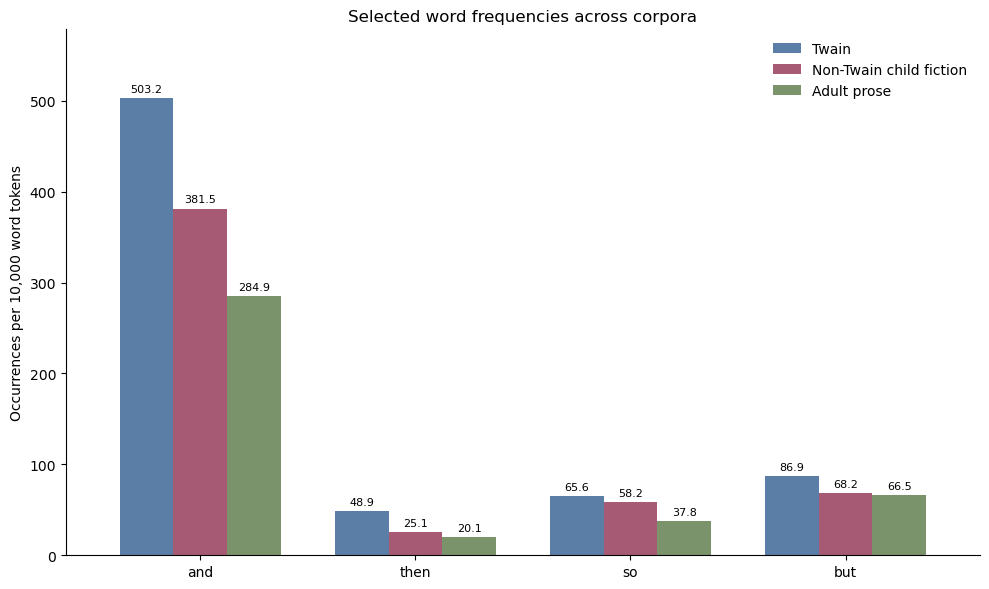

Figure saved to: /Users/manalaltammami/Desktop/twain_child_corpus/coordination_narrative_results/connectives_narrative.png


In [10]:
import matplotlib.pyplot as plt
from pathlib import Path

# Use the calculated results directly—no manually entered rates.
chart_data = df_connectives.set_index("Word")[
    ["Twain per 10k", "Child per 10k", "Adult per 10k"]
].rename(columns={
    "Twain per 10k": "Twain",
    "Child per 10k": "Non-Twain child fiction",
    "Adult per 10k": "Adult prose"
})

ax = chart_data.plot.bar(
    figsize=(10, 6),
    color=["#5B7EA6", "#A65A73", "#7A936B"],
    width=0.75,
    rot=0
)

ax.set_xlabel("")
ax.set_ylabel("Occurrences per 10,000 word tokens")
ax.set_title("Selected word frequencies across corpora")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)

ax.margins(y=0.15)
plt.tight_layout()

output_path = OUTPUT_DIR / "connectives_narrative.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved to:", output_path)


In [31]:
# Per-novel connective frequencies for the three Twain novels.
# Uses the same files, tokenizer, and verified totals as Step 1.

novel_names = {
    "Tom_Sawyer_narrative.txt": "Tom Sawyer",
    "Huckleberry_Finn_narrative.txt": "Huckleberry Finn",
    "Prince_and_the_Pauper_narrative.txt": "The Prince and the Pauper",
}

novel_rows = []

for filename in twain_files:
    text = (BASE_PATH / filename).read_text(encoding="utf-8")
    tokens = tokenize(text)
    total = len(tokens)

    if total != EXPECTED_BOOK_TOKENS[filename]:
        raise ValueError(f"Unexpected token total for {filename}")

    freq = Counter(tokens)

    for word in ["and", "then", "so", "but"]:
        novel_rows.append({
            "Novel": novel_names[filename],
            "Tokens": total,
            "Word": word,
            "Count": freq[word],
            "Per 10,000": freq[word] / total * 10000,
        })

df_novel_connectives = pd.DataFrame(novel_rows)

print(
    df_novel_connectives.round(3).to_string(index=False)
)

                    Novel  Tokens Word  Count  Per 10,000
               Tom Sawyer   70518  and   3087     437.761
               Tom Sawyer   70518 then    307      43.535
               Tom Sawyer   70518   so    355      50.342
               Tom Sawyer   70518  but    580      82.249
         Huckleberry Finn  110729  and   6264     565.705
         Huckleberry Finn  110729 then    599      54.096
         Huckleberry Finn  110729   so    960      86.698
         Huckleberry Finn  110729  but   1035      93.471
The Prince and the Pauper   67007  and   3140     468.608
The Prince and the Pauper   67007 then    308      45.965
The Prince and the Pauper   67007   so    313      46.712
The Prince and the Pauper   67007  but    542      80.887


In [33]:
import random

passage_rows = []

for filename in twain_files:
    text = (BASE_PATH / filename).read_text(encoding="utf-8")
    paragraphs = re.split(r"\n\s*\n", text.strip())
    candidates = []

    for paragraph_number, paragraph in enumerate(paragraphs, start=1):
        tokens = tokenize(paragraph)
        and_count = tokens.count("and")

        # A consistent rule for finding manageable passages.
        if 40 <= len(tokens) <= 200 and and_count >= 4:
            candidates.append({
                "Novel": novel_names[filename],
                "Paragraph": paragraph_number,
                "Tokens": len(tokens),
                "And count": and_count,
                "Passage": paragraph.strip(),
            })

    print(f"\n=== {novel_names[filename]} ===")
    print(f"Qualifying paragraphs: {len(candidates)}")

    rng = random.Random(42)
    selected = rng.sample(candidates, min(3, len(candidates)))

    for row in sorted(selected, key=lambda item: item["Paragraph"]):
        passage_rows.append(row)
        print(
            f"\nParagraph {row['Paragraph']} | "
            f"{row['Tokens']} tokens | "
            f"{row['And count']} occurrences of 'and'"
        )
        print(row["Passage"])

df_and_passages = pd.DataFrame(passage_rows)


=== Tom Sawyer ===
Qualifying paragraphs: 237

Paragraph 104 | 97 tokens | 10 occurrences of 'and'
The new boy took two broad coppers out of his pocket and held them out
with derision. Tom struck them to the ground. In an instant both boys
were rolling and tumbling in the dirt, gripped together like cats; and
for the space of a minute they tugged and tore at each other’s hair and
clothes, punched and scratched each other’s nose, and covered themselves
with dust and glory. Presently the confusion took form, and through the
fog of battle Tom appeared, seated astride the new boy, and pounding him
with his fists. “Holler ’nuff!” said he.

Paragraph 206 | 77 tokens | 7 occurrences of 'and'
Mary gave him a tin basin of water and a piece of soap, and he went
outside the door and set the basin on a little bench there; then he
dipped the soap in the water and laid it down; turned up his sleeves;
poured out the water on the ground, gently, and then entered the kitchen
and began to wipe his face

In [35]:
# Per-book frequencies in both comparison corpora.
# Uses the same narrative files and tokenizer as the main analysis.

comparison_rows = []

for corpus_label, file_list in [
    ("Non-Twain child fiction", child_files),
    ("Adult fiction", adult_files),
]:
    for filename in file_list:
        text = (BASE_PATH / filename).read_text(encoding="utf-8")
        tokens = tokenize(text)
        total = len(tokens)

        if total != EXPECTED_BOOK_TOKENS[filename]:
            raise ValueError(
                f"Unexpected token total for {filename}"
            )

        freq = Counter(tokens)

        row = {
            "Corpus": corpus_label,
            "Text": filename.removesuffix("_narrative.txt").replace("_", " "),
            "Tokens": total,
        }

        for word in ["and", "then", "so", "but"]:
            row[f"{word} count"] = freq[word]
            row[f"{word} per 10k"] = freq[word] / total * 10000

        comparison_rows.append(row)

df_comparison_books = pd.DataFrame(comparison_rows)

# Display rates; preserve exact counts in the saved CSV.
rate_columns = [
    "Text", "Tokens",
    "and per 10k", "then per 10k",
    "so per 10k", "but per 10k",
]

for label in ["Non-Twain child fiction", "Adult fiction"]:
    print(f"\n=== {label.upper()} ===\n")
    print(
        df_comparison_books.loc[
            df_comparison_books["Corpus"] == label,
            rate_columns,
        ].round(3).to_string(index=False)
    )

results_folder = BASE_PATH / "coordination_narrative_results"
results_folder.mkdir(exist_ok=True)

output_file = results_folder / "comparison_per_book_connectives.csv"
df_comparison_books.to_csv(output_file, index=False)

print("\nSaved:", output_file)


=== NON-TWAIN CHILD FICTION ===

                  Text  Tokens  and per 10k  then per 10k  so per 10k  but per 10k
           Ragged Dick   47722      245.379        17.392      39.814       73.970
          Little Women  185825      432.342        19.965      60.971       78.784
 An Old Fashioned Girl  101818      405.331        21.018      70.714       75.036
            Toby Tyler   50233      293.034        38.222      52.555       56.138
   Five Little Peppers   69400      352.594        46.254      63.833       44.669
     Hoosier Schoolboy   36080      343.404        27.716      34.645       81.208
Little Lord Fauntleroy   58627      432.906        18.080      59.188       47.248
    The Story of Patsy   11359      331.015        17.607      38.736       73.070

=== ADULT FICTION ===

                Text  Tokens  and per 10k  then per 10k  so per 10k  but per 10k
        Silas Lapham  129245      299.277        27.158      37.835       79.771
    Ministers Charge  115995     

In [37]:
import random

comparison_passages = []
sampling_summary = []

for corpus_label, file_list in [
    ("Non-Twain child fiction", child_files),
    ("Adult fiction", adult_files),
]:
    for filename in file_list:
        text = (BASE_PATH / filename).read_text(encoding="utf-8")
        paragraphs = re.split(r"\n\s*\n", text.strip())
        candidates = []

        for number, paragraph in enumerate(paragraphs, start=1):
            tokens = tokenize(paragraph)
            and_count = tokens.count("and")

            # Same selection rule used for the Twain passages.
            if 40 <= len(tokens) <= 200 and and_count >= 4:
                candidates.append({
                    "Corpus": corpus_label,
                    "File": filename,
                    "Paragraph": number,
                    "Tokens": len(tokens),
                    "And count": and_count,
                    "Passage": paragraph.strip(),
                })

        rng = random.Random(42)
        selected = rng.sample(candidates, min(3, len(candidates)))

        comparison_passages.extend(
            sorted(selected, key=lambda row: row["Paragraph"])
        )

        sampling_summary.append({
            "File": filename,
            "Qualifying paragraphs": len(candidates),
            "Selected paragraphs": len(selected),
        })

df_comparison_passages = pd.DataFrame(comparison_passages)
df_sampling_summary = pd.DataFrame(sampling_summary)

results_folder = BASE_PATH / "coordination_narrative_results"
results_folder.mkdir(exist_ok=True)

df_comparison_passages.to_csv(
    results_folder / "comparison_and_passages.csv", index=False
)
df_sampling_summary.to_csv(
    results_folder / "comparison_passage_sampling.csv", index=False
)

print(df_sampling_summary.to_string(index=False))

print("\n=== DEEPHAVEN: SELECTED PASSAGES ===")

for row in comparison_passages:
    if row["File"] == "Deephaven_narrative.txt":
        print(
            f"\nParagraph {row['Paragraph']} | "
            f"{row['Tokens']} tokens | "
            f"{row['And count']} occurrences of 'and'"
        )
        print(row["Passage"])

print("\nFiles saved in:", results_folder)

                                File  Qualifying paragraphs  Selected paragraphs
           Ragged_Dick_narrative.txt                     59                    3
          Little_Women_narrative.txt                    658                    3
 An_Old_Fashioned_Girl_narrative.txt                    309                    3
            Toby_Tyler_narrative.txt                     83                    3
   Five_Little_Peppers_narrative.txt                    134                    3
     Hoosier_Schoolboy_narrative.txt                     95                    3
Little_Lord_Fauntleroy_narrative.txt                    172                    3
    The_Story_of_Patsy_narrative.txt                     31                    3
          Silas_Lapham_narrative.txt                    242                    3
      Ministers_Charge_narrative.txt                    238                    3
   Hazard_New_Fortunes_narrative.txt                    230                    3
    Portrait_of_a_Lady_narra

In [39]:
# Diagnostic check only: candidate forms are NOT automatically
# treated as equivalents of "and".

text = (BASE_PATH / "Conjure_Woman_narrative.txt").read_text(
    encoding="utf-8"
)
normalized = text.lower().replace("’", "'")

# Keeps leading/trailing apostrophes for this spelling check.
diagnostic_pattern = re.compile(r"(?<![a-z])'?[a-z]+(?:'[a-z]+)*'?(?![a-z])")
matches = list(diagnostic_pattern.finditer(normalized))

candidates = ["and", "en", "an", "an'", "'n", "n"]
diagnostic_freq = Counter(match.group() for match in matches)

print("Candidate spellings — not yet verified as conjunctions:\n")

for form in candidates:
    print(f"{form!r}: {diagnostic_freq[form]:,}")

# Display up to five reproducibly selected contexts per candidate.
import random

for form in candidates:
    if form == "and":
        continue

    hits = [match for match in matches if match.group() == form]
    rng = random.Random(42)
    selected = rng.sample(hits, min(5, len(hits)))

    print(f"\n=== {form!r}: {len(hits):,} candidate occurrences ===")

    for match in sorted(selected, key=lambda item: item.start()):
        start = max(0, match.start() - 90)
        end = min(len(text), match.end() + 90)

        before = text[start:match.start()].replace("\n", " ")
        hit = text[match.start():match.end()]
        after = text[match.end():end].replace("\n", " ")

        print(f"\n…{before} [{hit}] {after}…")

Candidate spellings — not yet verified as conjunctions:

'and': 291
'en': 1,421
'an': 33
"an'": 1
"'n": 38
'n': 0

=== 'en': 1,421 candidate occurrences ===

…r had b'en er wukkin'. Den one er de nigger chilluns runned away fum de quarters one day,  [en]  got in de scuppernon's, en died de nex' week. W'ite folks say he die' er de fevuh, but de…

… b'lieve it's no sin fer ter do; en ef you doan wanter be sent roun' fum pillar ter pos',  [en]  ef you doan wanter go down ter Robeson, I kin fix things so you won't haf ter. Ef you'll …

… in his sleep, widout knowin' it. Wen Solomon seed he 'd done eat de 'tater, he went back  [en]  tol' Aun' Peggy, en den went home ter his cabin ter sleep, 'way 'long 'bout two o'clock i…

…d ef de niggers want ter hab a dance in de big ba'n any Sad'day night, dey mought hab it.  [En]  bimeby, w'en Solomon seed how good Mars Jeems wuz, he ax' 'im ef he would n' please sen' …

… mo' triflin', 'tel he got de name er bein' de mos' no 'countes' nigger on de pla

In [13]:
from pathlib import Path
import re
import pandas as pd
from lexicalrichness import LexicalRichness

corpus_folder = Path.home() / "Desktop" / "twain_child_corpus"
downloads_folder = Path.home() / "Downloads"

connectives = ["and", "then", "so", "but"]
token_pattern = re.compile(r"[a-z]+(?:['-][a-z]+)*")

def word_tokens(text):
    return token_pattern.findall(text.lower().replace("’", "'"))

def diversity(tokens):
    lex = LexicalRichness(
        " ".join(tokens),
        preprocessor=None,
        tokenizer=str.split,
    )
    return lex.mtld(threshold=0.72), lex.hdd(draws=42)

def load_passages(text_filename, csv_filename):
    text = (corpus_folder / text_filename).read_text(
        encoding="utf-8"
    )
    passages = pd.read_csv(
        downloads_folder / csv_filename
    ).sort_values("Start")

    required = {
        "Start", "End", "Quoted passage",
        "Speaker", "Speech included",
    }
    missing = required - set(passages.columns)
    if missing:
        raise ValueError(f"{csv_filename}: missing columns {missing}")

    previous_end = 0

    for _, row in passages.iterrows():
        start, end = int(row["Start"]), int(row["End"])

        assert previous_end <= start < end <= len(text), (
            f"{csv_filename}: overlapping or invalid positions."
        )
        assert text[start:end] == str(row["Quoted passage"]), (
            f"{csv_filename}: text mismatch at position {start}."
        )

        previous_end = end

    return text, passages

# Huck Finn: separate unquoted text and attributed dialogue.
huck_text, huck_passages = load_passages(
    "Huckleberry_Finn_narrative.txt",
    "Huck_passages_REVIEWED.csv",
)

unquoted_parts = []
quoted_parts = []
huck_dialogue_parts = []
previous_end = 0

for _, row in huck_passages.iterrows():
    start, end = int(row["Start"]), int(row["End"])

    unquoted_parts.append(huck_text[previous_end:start])
    quoted_parts.append(huck_text[start:end])

    included = (
        str(row["Speech included"]).strip().lower() == "true"
    )
    if included and str(row["Speaker"]).strip() == "Huck":
        huck_dialogue_parts.append(huck_text[start:end])

    previous_end = end

unquoted_parts.append(huck_text[previous_end:])

# Tom Sawyer: retain Tom's attributed dialogue.
tom_text, tom_passages = load_passages(
    "Tom_Sawyer_narrative.txt",
    "Tom_passages_REVIEWED_Mary_Polly.csv",
)

tom_selected = tom_passages.loc[
    tom_passages["Speech included"]
    .astype(str).str.strip().str.lower().eq("true")
    & tom_passages["Speaker"]
    .fillna("").str.strip().eq("Tom Sawyer")
]

tom_dialogue_parts = []

for _, row in tom_selected.iterrows():
    passage = str(row["Quoted passage"])

    if "Nonspoken bracketed wording" in tom_selected.columns:
        wording = row["Nonspoken bracketed wording"]
        if pd.notna(wording) and str(wording).strip():
            passage = passage.replace(str(wording), "")

    tom_dialogue_parts.append(passage)

sections = {
    "Unquoted (mainly Huck's narration)": " ".join(unquoted_parts),
    "All quoted passages in Huck Finn": " ".join(quoted_parts),
    "Huck's attributed dialogue": " ".join(huck_dialogue_parts),
    "Tom's dialogue in Tom Sawyer": " ".join(tom_dialogue_parts),
}

expected_tokens = {
    "Unquoted (mainly Huck's narration)": 71583,
    "All quoted passages in Huck Finn": 39146,
    "Huck's attributed dialogue": 8253,
    "Tom's dialogue in Tom Sawyer": 8127,
}

frequency_rows = []
diversity_rows = []

for section, section_text in sections.items():
    tokens = word_tokens(section_text)

    if len(tokens) != expected_tokens[section]:
        raise ValueError(
            f"{section}: found {len(tokens):,} tokens; "
            f"expected {expected_tokens[section]:,}. "
            "Check the source text and passage file."
        )

    filtered = [
        word for word in tokens
        if word not in connectives
    ]

    for term in connectives:
        count = tokens.count(term)
        frequency_rows.append({
            "Section": section,
            "Connective": term,
            "Count": count,
            "Per 10k": round(count / len(tokens) * 10000, 2),
        })

    mtld, hdd = diversity(tokens)
    mtld_removed, hdd_removed = diversity(filtered)

    diversity_rows.append({
        "Section": section,
        "Tokens": len(tokens),
        "MTLD": round(mtld, 2),
        "MTLD without connectives": round(mtld_removed, 2),
        "HD-D": round(hdd, 4),
        "HD-D without connectives": round(hdd_removed, 4),
    })

print("CONNECTIVE FREQUENCIES")
print(pd.DataFrame(frequency_rows).to_string(index=False))

print("\nLEXICAL DIVERSITY")
print(pd.DataFrame(diversity_rows).to_string(index=False))

CONNECTIVE FREQUENCIES
                           Section Connective  Count  Per 10k
Unquoted (mainly Huck's narration)        and   4878   681.45
Unquoted (mainly Huck's narration)       then    495    69.15
Unquoted (mainly Huck's narration)         so    711    99.33
Unquoted (mainly Huck's narration)        but    718   100.30
  All quoted passages in Huck Finn        and   1386   354.06
  All quoted passages in Huck Finn       then    104    26.57
  All quoted passages in Huck Finn         so    249    63.61
  All quoted passages in Huck Finn        but    317    80.98
        Huck's attributed dialogue        and    334   404.70
        Huck's attributed dialogue       then     33    39.99
        Huck's attributed dialogue         so     57    69.07
        Huck's attributed dialogue        but     76    92.09
      Tom's dialogue in Tom Sawyer        and    259   318.69
      Tom's dialogue in Tom Sawyer       then     25    30.76
      Tom's dialogue in Tom Sawyer         so  

In [17]:
from pathlib import Path
import re
import pandas as pd
from lexicalrichness import LexicalRichness

downloads = Path.home() / "Downloads"
corpus_folder = Path.home() / "Desktop" / "twain_child_corpus"

connectives = ["and", "then", "so", "but"]
token_pattern = re.compile(r"[a-z]+(?:['-][a-z]+)*")

def word_tokens(text):
    return token_pattern.findall(text.lower().replace("’", "'"))

def diversity(tokens):
    lex = LexicalRichness(
        " ".join(tokens),
        preprocessor=None,
        tokenizer=str.split,
    )
    return lex.mtld(threshold=0.72), lex.hdd(draws=42)

books = [
    {
        "Novel": "Tom Sawyer",
        "Text": "Tom_Sawyer_narrative.txt",
        "CSV": "Tom_passages_REVIEWED_Mary_Polly.csv",
        "Speakers": {
            "Tom Sawyer": "Tom Sawyer",
            "Huck Finn": "Huck",
        },
    },
    {
        "Novel": "Prince and Pauper",
        "Text": "Prince_and_the_Pauper_narrative.txt",
        "CSV": "Prince_all_quoted_passages_20261101_025412_270072.csv",
        "Speakers": {
            "Tom Canty": "Tom Canty",
            "Edward": "Edward",
        },
    },
]

frequency_rows = []
diversity_rows = []

for book in books:
    text = (corpus_folder / book["Text"]).read_text(encoding="utf-8")
    passages = pd.read_csv(downloads / book["CSV"]).sort_values("Start")

    required = {"Start", "End", "Quoted passage", "Speaker"}
    missing = required - set(passages.columns)
    if missing:
        raise ValueError(f"{book['Novel']}: missing columns {missing}")

    # Check that positions belong to this version of the text.
    previous_end = 0
    for _, row in passages.iterrows():
        start, end = int(row["Start"]), int(row["End"])

        assert previous_end <= start < end <= len(text), (
            f"{book['Novel']}: overlapping or invalid positions."
        )
        assert text[start:end] == str(row["Quoted passage"]), (
            f"{book['Novel']}: text mismatch at position {start}."
        )
        previous_end = end

    # Use existing speech-inclusion decisions where available.
    if "Speech included" in passages.columns:
        included = (
            passages["Speech included"]
            .astype(str).str.strip().str.lower().eq("true")
        )
        speech = passages.loc[included].copy()
    else:
        speech = passages.copy()
        print(
            f"NOTE: {book['Novel']} has no 'Speech included' column. "
            "Results use attributed quoted passages."
        )

    speech["Speaker"] = speech["Speaker"].fillna("").str.strip()

    for speaker_label, display_name in book["Speakers"].items():
        selected = speech.loc[speech["Speaker"].eq(speaker_label)]

        if selected.empty:
            raise ValueError(
                f"{book['Novel']}: no passages labeled {speaker_label!r}. "
                f"Available labels: {speech['Speaker'].unique().tolist()}"
            )

        # Remove bracketed nonspoken wording if explicitly recorded.
        parts = []
        for _, row in selected.iterrows():
            passage = str(row["Quoted passage"])
            if "Nonspoken bracketed wording" in selected.columns:
                wording = row["Nonspoken bracketed wording"]
                if pd.notna(wording) and str(wording).strip():
                    passage = passage.replace(str(wording), "")
            parts.append(passage)

        tokens = word_tokens(" ".join(parts))
        filtered = [word for word in tokens if word not in connectives]

        if len(filtered) < 42:
            raise ValueError(f"Too few tokens for {display_name}.")

        for term in connectives:
            count = tokens.count(term)
            frequency_rows.append({
                "Novel": book["Novel"],
                "Speaker": display_name,
                "Connective": term,
                "Count": count,
                "Per 10k": round(count / len(tokens) * 10000, 2),
            })

        mtld, hdd = diversity(tokens)
        mtld_removed, hdd_removed = diversity(filtered)

        diversity_rows.append({
            "Novel": book["Novel"],
            "Speaker": display_name,
            "Tokens": len(tokens),
            "MTLD": round(mtld, 2),
            "MTLD without connectives": round(mtld_removed, 2),
            "HD-D": round(hdd, 4),
            "HD-D without connectives": round(hdd_removed, 4),
        })

print("\nCONNECTIVE FREQUENCIES")
print(pd.DataFrame(frequency_rows).to_string(index=False))

print("\nLEXICAL DIVERSITY")
print(pd.DataFrame(diversity_rows).to_string(index=False))

NOTE: Prince and Pauper has no 'Speech included' column. Results use attributed quoted passages.

CONNECTIVE FREQUENCIES
            Novel    Speaker Connective  Count  Per 10k
       Tom Sawyer Tom Sawyer        and    259   318.69
       Tom Sawyer Tom Sawyer       then     25    30.76
       Tom Sawyer Tom Sawyer         so     46    56.60
       Tom Sawyer Tom Sawyer        but     77    94.75
       Tom Sawyer       Huck        and    154   337.05
       Tom Sawyer       Huck       then      8    17.51
       Tom Sawyer       Huck         so     37    80.98
       Tom Sawyer       Huck        but     40    87.55
Prince and Pauper  Tom Canty        and    120   378.67
Prince and Pauper  Tom Canty       then      9    28.40
Prince and Pauper  Tom Canty         so     18    56.80
Prince and Pauper  Tom Canty        but     32   100.98
Prince and Pauper     Edward        and    135   383.41
Prince and Pauper     Edward       then     10    28.40
Prince and Pauper     Edward         so